# Atelier de pretraitement : choisir, regler et verifier

Ce notebook se lance depuis la racine du depot (comme les scripts). Il montre :
1. le catalogue des operations et leur effet sur de vraies images ;
2. le reglage d'un parametre (grille fixe, et curseurs ipywidgets en session interactive) ;
3. la correction d'illumination (shading) sur un vignettage artificiel, puis sur une vraie image ;
4. le retrait d'un motif periodique par FFT ;
5. le traitement par tuiles d'une grande image ;
6. le passage au YAML et a la carte du modele ;
7. le jugement a la metrique (resultats de compare.py).

In [1]:
from pathlib import Path  # Path : represente un chemin de fichier, fonctionne sous Windows comme sous Linux

import matplotlib.pyplot as plt  # matplotlib : trace les figures
import numpy as np  # numpy : calcul sur des tableaux de nombres (une image = un tableau)
from IPython.display import Image, display  # affiche une image (ici des octets JPEG) dans le notebook

from vtb.core.config import load_config  # lit le fichier YAML et verifie chaque reglage

# lecture d'une image ; conversion en 8 bits (0-255) pour l'affichage ; ecriture d'une image sur disque
from vtb.io.images import read_image, to_uint8, write_image

# Pipeline : enchaine des operations nommees ; get_op : fiche d'une operation par son nom ; list_ops : le catalogue
from vtb.preprocess import Pipeline, get_op, list_ops
from vtb.preprocess.benchmark import PreprocessingConfig  # le modele de configuration de la recette
from vtb.preprocess.gallery import family_sheet, figure_bytes  # planche avant / apres d'une famille ; figure -> octets JPEG
from vtb.preprocess.ops.illumination import apply_vignetting  # ajoute un vignettage artificiel (bords assombris)
from vtb.preprocess.tiles import stitch_maps, tile_image  # decoupe une grande image en tuiles ; recolle les cartes des tuiles

plt.rcParams["figure.dpi"] = 72  # figures plus legeres dans le .ipynb enregistre
try:  # figures en JPEG dans le notebook : 4 a 5 fois plus legeres que le PNG pour des photos
    from matplotlib_inline.backend_inline import set_matplotlib_formats  # reglage du format des figures dans Jupyter

    set_matplotlib_formats("jpeg")  # les figures affichees seront encodees en JPEG
except ImportError:  # si ce module n'est pas installe (hors Jupyter)
    pass  # on ne fait rien : les figures restent en PNG

CONFIG = load_config("recipes/preprocessing/configs/steel_gray.yaml", PreprocessingConfig)  # config de la recette (acier, gris)
OUT = Path(CONFIG.runtime.output_dir) / "notebook"  # dossier des fichiers produits par ce notebook
OUT.mkdir(parents=True, exist_ok=True)  # le cree (et ses parents) s'il n'existe pas
table = list_ops()  # tableau de toutes les operations : famille, nom, resume, parametres par defaut
print(len(table), "operations au catalogue")  # combien d'operations sont disponibles
table[["family", "name", "summary"]]  # derniere ligne de la cellule : le notebook affiche ces 3 colonnes

49 operations au catalogue


,family,name,summary
0,alignement,absdiff_reference,Difference absolue avec une piece de reference...
1,alignement,align_ecc,Recale l'image sur une image de reference par ...
2,alignement,align_orb,Recale l'image sur une reference par points OR...
3,contours,canny,Detecteur de Canny : aretes fines et binaires ...
4,contours,laplacian_edges,Valeur absolue du laplacien : repond aux point...
5,contours,scharr,Norme du gradient de Scharr : plus precise que...
6,contours,sobel,Norme du gradient de Sobel 3x3 ; gain 0.25 ram...
7,contraste,clahe,Egalisation adaptative limitee (CLAHE) : contr...
8,contraste,equalize_hist,Egalisation d'histogramme globale : repartit l...
9,couleur,extract_channel,"Un seul canal d'un espace de couleur (rgb, hsv..."


## 1. Une famille sur ses propres images

La premiere ligne montre les originaux ; chaque ligne suivante, une operation avec ses
parametres par defaut. Remplacer la liste `images` par des images du site.

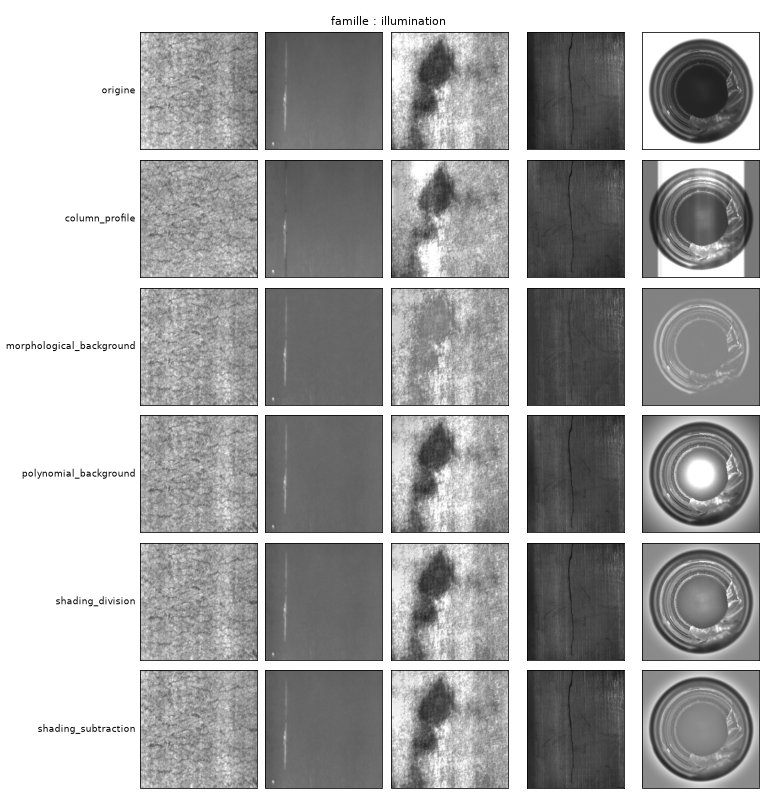

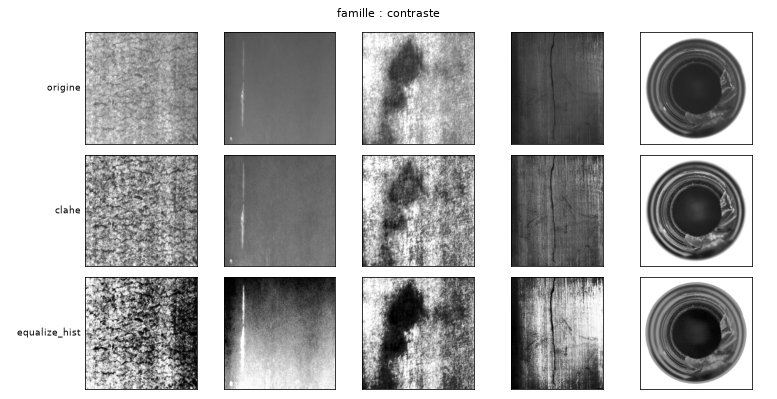

In [2]:
images = [read_image(p, color=CONFIG.data.color) for p in CONFIG.gallery.images]  # images d'exemple listees dans le YAML
for family in ("illumination", "contraste"):  # pour deux familles d'operations
    # toutes les operations de la famille avec leurs parametres par defaut ({}), sauf flat_field (il lui faut une image de fond)
    operations = [(name, {}) for name in table.loc[table["family"] == family, "name"] if name != "flat_field"]
    # dessine la planche (originaux puis une ligne par operation), la convertit en JPEG et l'affiche
    display(Image(figure_bytes(family_sheet(images, operations, f"famille : {family}")), format="jpeg"))

## 2. Regler un parametre a l'oeil... puis a la metrique

Les curseurs permettent de sentir l'effet d'un parametre (ici CLAHE et la correction
d'illumination). Le reglage definitif se fait ensuite avec `compare.py`, sur la validation.

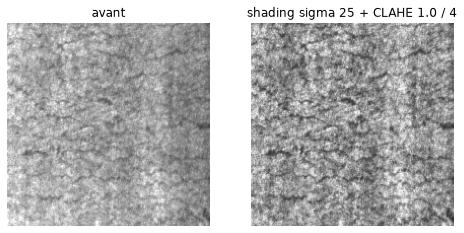

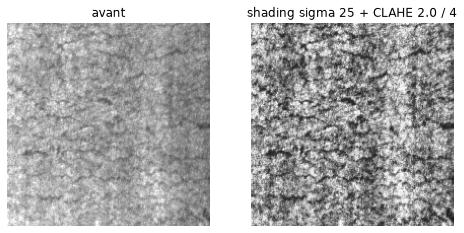

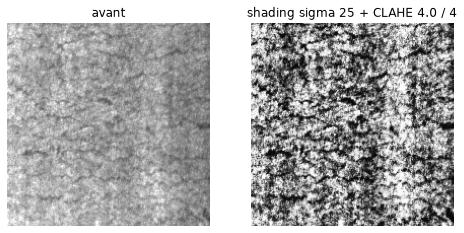

In [3]:
sample = images[0]  # la 1re image d'exemple sert pour tous les essais de reglage


def show_pair(before: np.ndarray, after: np.ndarray, title: str) -> None:  # affiche avant / apres cote a cote ; ne renvoie rien
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))  # 2 cases cote a cote
    for ax, img, name in zip(axes, (before, after), ("avant", title)):  # pour chaque case, son image et son titre
        # affiche en gris sur l'echelle fixe 0-255 (vmin / vmax) : les deux images sont comparables
        ax.imshow(to_uint8(img), cmap="gray", vmin=0, vmax=255)
        ax.set_title(name)  # titre de la case
        ax.axis("off")  # masque les axes gradues
    plt.show()  # affiche la figure


def tune(clip_limit: float = 2.0, tile_grid: int = 4, sigma: float = 25.0) -> None:  # applique un reglage et montre le resultat
    pipeline = Pipeline(  # pretraitement en deux operations, appliquees dans l'ordre
        [  # liste des operations : chacune est un dict {"name": nom, autres cles: reglages}
            # corrige l'eclairage inegal en divisant par le fond tres flou (sigma = taille du flou en pixels)
            {"name": "shading_division", "sigma": sigma, "downscale": 2},
            # CLAHE : renforce le contraste local par tuiles ; clip_limit borne l'amplification (et donc le bruit)
            {"name": "clahe", "clip_limit": clip_limit, "tile_grid": tile_grid},
        ]
    )
    show_pair(sample, pipeline(sample), f"shading sigma {sigma:.0f} + CLAHE {clip_limit:.1f} / {tile_grid}")  # avant / apres


for clip in (1.0, 2.0, 4.0):  # grille fixe, visible meme dans un notebook lu sans noyau
    tune(clip_limit=clip)  # un essai par valeur de clip_limit (les autres parametres gardent leur valeur par defaut)


def sliders() -> None:  # affiche des curseurs relies a tune ; ne renvoie rien
    """Curseurs ipywidgets pour regler les trois parametres a la main (session interactive uniquement)."""
    from ipywidgets import FloatSlider, IntSlider, interact  # ipywidgets : curseurs et boutons dans un notebook

    interact(  # relance tune a chaque mouvement d'un curseur
        tune,  # la fonction a appeler
        clip_limit=FloatSlider(value=2.0, min=0.5, max=8.0, step=0.5),  # curseur a virgule pour clip_limit
        tile_grid=IntSlider(value=4, min=2, max=16),  # curseur entier pour la grille de tuiles de CLAHE
        sigma=FloatSlider(value=25, min=5, max=100, step=5),  # curseur pour le flou du fond
    )


# Dans VS Code ou Jupyter, decommenter la ligne suivante pour obtenir les curseurs (ils ne
# s'affichent pas dans un notebook execute sans interface, d'ou l'appel laisse en commentaire).
# sliders()

## 3. Correction d'illumination (shading)

On fabrique un eclairage inegal connu (vignettage), puis on compare les six corrections.
Pour `flat_field`, l'image de reference est un fond uniforme sous le meme vignettage : c'est ce
qu'on obtiendrait en photographiant une lame vide ou une plaque blanche.

Le reglage de sigma : plus grand que les objets (sinon le "fond" les contient et la division les
efface), plus petit que l'echelle de variation de l'eclairage (sinon le fond estime est plat et
rien n'est corrige). Sur ces images de 200 px a texture fine, sigma = 12 convient.

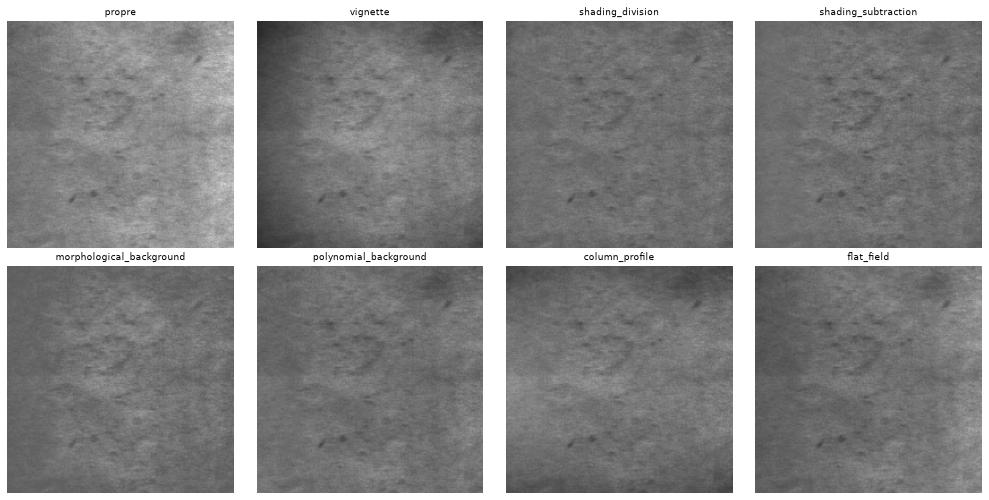

In [4]:
clean = read_image("data/raw/neu_cls_flat/rolled/RS_1.bmp", color="gray")  # image d'acier lamine, eclairage regulier
vignetted = apply_vignetting(clean, strength=0.6)  # la meme avec les bords assombris (eclairage inegal connu)
flat = apply_vignetting(np.full_like(clean, 200), strength=0.6)  # fond uniforme (200 partout) sous le meme vignettage
write_image(OUT / "flat_reference.png", flat)  # enregistre ce fond : flat_field le relit depuis un fichier
variants = {  # dict {nom de l'operation: ses parametres} : les six corrections a comparer
    "shading_division": {"sigma": 12, "downscale": 2},  # divise par le fond flou (eclairage multiplicatif)
    "shading_subtraction": {"sigma": 12, "downscale": 2},  # soustrait le fond flou (eclairage additif)
    "morphological_background": {"kernel": 41},  # fond estime par morphologie (disque de 41 px, plus grand que les objets)
    "polynomial_background": {"order": 2},  # fond modelise par une surface polynomiale de degre 2
    "column_profile": {},  # divise chaque colonne par son profil median (camera lineaire)
    "flat_field": {"flat_path": str(OUT / "flat_reference.png")},  # divise par une vraie image de fond
}
# applique chaque correction a l'image vignettee ; get_op(nom).func = la fonction Python de l'operation
corrected = {name: get_op(name).func(vignetted, **params) for name, params in variants.items()}
fig, axes = plt.subplots(2, 4, figsize=(14, 7))  # grille 2 x 4 = 8 cases (propre, vignettee, 6 corrections)
panels = [("propre", clean), ("vignette", vignetted), *corrected.items()]  # couples (titre, image) a afficher
for ax, (name, img) in zip(axes.ravel(), panels):  # pour chaque case (grille mise a plat) et chaque couple
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)  # affiche en gris sur l'echelle fixe 0-255
    ax.set_title(name, fontsize=9)  # titre de la case
    ax.axis("off")  # masque les axes gradues
plt.tight_layout()  # resserre les cases
plt.show()  # affiche la figure

Le profil moyen d'une ligne a l'autre le montre mieux que l'oeil : apres correction, le profil
doit etre plat (aux details de la texture pres).

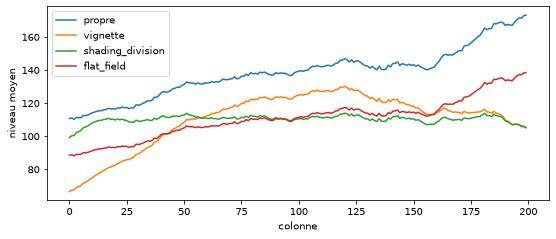

propre                     ecart centre / coins :   1.1 niveaux
vignette                   ecart centre / coins :  60.1 niveaux
shading_division           ecart centre / coins :   5.9 niveaux
shading_subtraction        ecart centre / coins :   4.7 niveaux
morphological_background   ecart centre / coins :  19.9 niveaux
polynomial_background      ecart centre / coins :   5.7 niveaux
column_profile             ecart centre / coins :  34.3 niveaux
flat_field                 ecart centre / coins :   1.0 niveaux


In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))  # un seul graphique, large et bas
for name, img in [  # pour chacune des 4 images a comparer
    ("propre", clean),  # reference sans vignettage
    ("vignette", vignetted),  # avec vignettage : profil en cloche
    ("shading_division", corrected["shading_division"]),  # apres division par le fond flou
    ("flat_field", corrected["flat_field"]),  # apres division par l'image de fond
]:
    ax.plot(img.astype(float).mean(axis=0), label=name)  # moyenne de chaque colonne (axis=0 : sur les lignes) -> une courbe
ax.set_xlabel("colonne")  # titre de l'axe horizontal
ax.set_ylabel("niveau moyen")  # titre de l'axe vertical
ax.legend()  # affiche la legende (noms des courbes)
plt.show()  # affiche la figure
for name, img in [("propre", clean), ("vignette", vignetted), *corrected.items()]:  # pour chaque image
    # ecart entre la luminosite du centre (carre 80-120) et celle des coins (carres 30 x 30) : 0 = eclairage uniforme
    gap = abs(img[80:120, 80:120].mean() - np.mean([img[:30, :30].mean(), img[-30:, -30:].mean()]))
    print(f"{name:26s} ecart centre / coins : {gap:5.1f} niveaux")  # nom aligne sur 26 caracteres, puis l'ecart

Sur une vraie image : la bouteille MVTec est eclairee par le dessous, le centre est beaucoup
plus clair que le bord. La division par un fond flou large rend le fond uniforme, la
soustraction garde mieux les contrastes locaux : on choisira a la metrique.

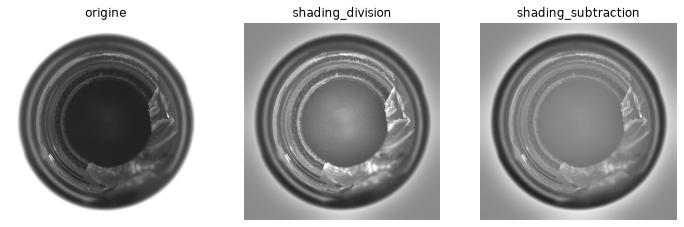

In [6]:
real = read_image("data/raw/mvtec_bottle/test/broken_large/000.png", color="gray")  # vraie bouteille, vue de dessus
real_variants = [("origine", real)] + [  # l'originale, puis les deux corrections
    (n, get_op(n).func(real, sigma=60, downscale=8))  # (nom, image corrigee) ; sigma 60 : fond tres flou ; downscale 8 : rapide
    for n in ("shading_division", "shading_subtraction")  # pour chacune des deux methodes
]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))  # 3 cases cote a cote
for ax, (name, img) in zip(axes, real_variants):  # pour chaque case et chaque couple (titre, image)
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)  # affiche en gris sur l'echelle fixe 0-255
    ax.set_title(name)  # titre de la case
    ax.axis("off")  # masque les axes gradues
plt.show()  # affiche la figure

## 4. Motif periodique : le coupe-bande FFT

Des rayures regulieres (traces de cylindres, defaut fixe d'une camera lineaire) font un pic
etroit dans le spectre. `fft_notch` le detecte et l'eteint ; le reste de l'image est conserve.

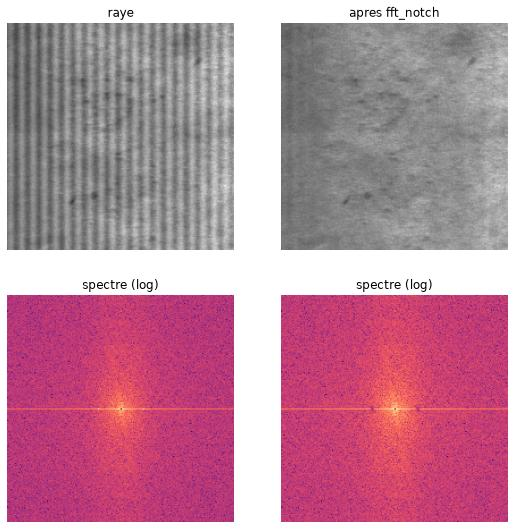

In [7]:
xx = np.arange(clean.shape[1])[None, :]  # numeros de colonne, en tableau d'une ligne (pour s'appliquer a toutes les lignes)
# ajoute des rayures verticales : sinus d'amplitude 25 niveaux, 20 periodes sur la largeur ; borne a 0-255, en 8 bits
striped = np.clip(clean.astype(float) + 25 * np.sin(2 * np.pi * 20 * xx / clean.shape[1]), 0, 255).astype(np.uint8)
notched = get_op("fft_notch").func(striped)  # FFT (decomposition en frequences) : detecte le pic des rayures et l'eteint


def log_spectrum(img: np.ndarray) -> np.ndarray:  # renvoie le spectre (amplitude des frequences) en echelle log, pour l'affichage
    # fft2 : passage en frequences ; fftshift : frequence 0 au centre ; abs : amplitude ; log1p : log(1 + x) ecrase les grands pics
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(img.astype(float) - img.mean()))))


fig, axes = plt.subplots(2, 2, figsize=(9, 9))  # grille 2 x 2 : images en haut, spectres en bas
for col, (name, img) in enumerate((("raye", striped), ("apres fft_notch", notched))):  # pour chaque image ; col = colonne
    axes[0][col].imshow(img, cmap="gray", vmin=0, vmax=255)  # 1re ligne : l'image
    axes[0][col].set_title(name)  # titre de la case
    axes[1][col].imshow(log_spectrum(img), cmap="magma")  # 2e ligne : son spectre (les rayures = deux points brillants)
    axes[1][col].set_title("spectre (log)")  # titre de la case
for ax in axes.ravel():  # pour chaque case de la grille
    ax.axis("off")  # masque les axes gradues
plt.show()  # affiche la figure

## 5. Grande image : tuiles avec recouvrement

On fabrique une "bande" longue en mettant bout a bout des tuiles magnetiques, on la decoupe en
tuiles de 256 px avec 25 % de recouvrement, on traite chaque tuile (ici un black-hat qui fait
ressortir les defauts sombres) et on recolle les cartes avec le maximum.

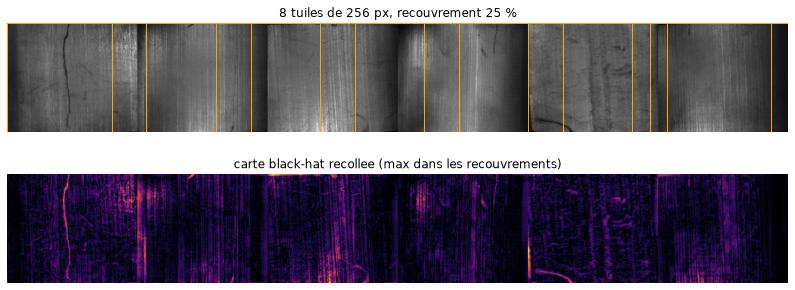

In [8]:
tiles_dir = Path("data/raw/magnetic_tile/MT_Crack/Imgs")  # dossier des images de tuiles fissurees
# Les tuiles n'ont pas toutes la meme taille : on les ramene a 200 x 240 avant de les mettre bout a bout.
strip = np.concatenate(  # colle des images en une seule grande image
    # les 6 premieres images (.jpg), lues en gris et redimensionnees a 200 x 240
    [get_op("resize").func(read_image(p, color="gray"), size=[200, 240]) for p in sorted(tiles_dir.glob("*.jpg"))[:6]],
    axis=1,  # axis=1 : cote a cote (dans le sens de la largeur)
)
# tuiles = positions (x, y, largeur, hauteur) ; pieces = les morceaux d'image ; overlap=0.25 : 25 % de recouvrement
tiles, pieces = tile_image(strip, tile_size=(strip.shape[0], 256), overlap=0.25)
maps = [get_op("blackhat").func(piece, kernel=15) for piece in pieces]  # black-hat : fait ressortir les petits objets sombres
# recolle les cartes des tuiles a leur place ; dans les recouvrements, garde la valeur la plus forte (prudent pour un defaut)
full = stitch_maps(maps, tiles, strip.shape[0], strip.shape[1], mode="max")
fig, axes = plt.subplots(2, 1, figsize=(14, 5))  # 2 cases l'une sous l'autre
axes[0].imshow(strip, cmap="gray")  # 1re case : la grande image
for tile in tiles:  # pour chaque tuile
    # dessine son contour en orange (rectangle vide) pour voir le decoupage et les recouvrements
    axes[0].add_patch(plt.Rectangle((tile.x, tile.y), tile.width, tile.height, fill=False, color="orange", lw=1))
axes[0].set_title(f"{len(tiles)} tuiles de 256 px, recouvrement 25 %")  # titre avec le nombre de tuiles
axes[1].imshow(full, cmap="inferno")  # 2e case : la carte recollee, en fausses couleurs
axes[1].set_title("carte black-hat recollee (max dans les recouvrements)")  # titre
for ax in axes:  # pour chaque case
    ax.axis("off")  # masque les axes gradues
plt.show()  # affiche la figure

## 6. Du reglage au YAML, et a la carte du modele

Un pipeline se declare dans le YAML de la recette (`preprocess:`). `describe()` donne la liste
exacte, parametres par defaut compris, recopiee dans `model_card.json` : c'est ce que le
programme de production (C#, C++) doit reproduire, dans cet ordre.

In [9]:
pipelines = CONFIG.build_pipelines()  # dict {nom: Pipeline} construit depuis la section pipelines du YAML
for name, pipeline in pipelines.items():  # pour chaque pipeline declare
    print(f"{name:14s} {pipeline}")  # nom (aligne sur 14 caracteres) et liste de ses operations
pipelines["shading_clahe"].describe()  # derniere ligne : affiche toutes les etapes avec tous leurs parametres

none           Pipeline()
stretch        Pipeline(percentile_stretch)
shading        Pipeline(shading_division)
clahe          Pipeline(clahe)
shading_clahe  Pipeline(shading_division -> clahe)
median_clahe   Pipeline(median_blur -> clahe)
dog            Pipeline(difference_of_gaussians)


[{'name': 'shading_division',
  'sigma': 25,
  'method': 'gaussian',
  'downscale': 2,
  'keep_mean': True},
 {'name': 'clahe', 'clip_limit': 2.0, 'tile_grid': 4}]

## 7. Juger a la metrique

`compare.py` extrait les caracteristiques d'un ResNet18 gele apres chaque pipeline et mesure
le F1 macro d'une regression logistique en validation croisee (5 plis, train + val, test non
lu). L'ecart-type dit si un ecart entre deux pipelines est reel ou du bruit.

In [10]:
for name in ("steel_gray", "steel_vignetted"):  # pour les deux experiences de compare.py
    path = Path("outputs/preprocessing") / name / "comparison.md"  # tableau ecrit par compare.py
    print(f"--- {name} ---")  # titre de la section
    print(  # affiche le tableau s'il existe, sinon la commande a lancer
        path.read_text()  # contenu du tableau...
        if path.exists()  # ... si le fichier existe
        # sinon : rappel de la commande qui produit ce tableau
        else f"(lancer : python recipes/preprocessing/scripts/compare.py --config recipes/preprocessing/configs/{name}.yaml)"
    )

--- steel_gray ---
| pipeline      |   f1_macro_mean |   f1_macro_std |   preprocess_ms_per_image |   seconds | steps                     |
|:--------------|----------------:|---------------:|--------------------------:|----------:|:--------------------------|
| none          |           0.956 |          0.029 |                     0.170 |    23.200 | (aucun)                   |
| stretch       |           0.952 |          0.016 |                     0.980 |    30.400 | percentile_stretch        |
| clahe         |           0.950 |          0.018 |                     0.590 |    25.700 | clahe                     |
| shading       |           0.947 |          0.018 |                     0.810 |    18.500 | shading_division          |
| shading_clahe |           0.947 |          0.026 |                     1.300 |    26.500 | shading_division -> clahe |
| dog           |           0.946 |          0.016 |                     0.720 |    40.500 | difference_of_gaussians   |
| median_clah